# EDA: Partial Discharge Signal Analysis

## Objective
- Load and analyze Q.lin datasets (1.0mm, 1.8mm, 2.0mm, 2.5mm)
- Explore noisy_minus10dB_18mm.mat
- Prepare data for MR-TAE-Fusion denoising + distance-based classification (4 classes)

In [ ]:
# Install required packages if needed
# !pip install scipy h5py mat73 matplotlib numpy pandas seaborn

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
import warnings
warnings.filterwarnings('ignore')

# Set plot style
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.figsize'] = (14, 6)
plt.rcParams['font.size'] = 12

# Data paths
DATA_DIR = Path(r'D:\New folder (2)\Data\OneDrive_2025-12-13')
QLIN_DIR = DATA_DIR / 'Datset from Q.lin'

print(f"Data directory: {DATA_DIR}")
print(f"Q.lin directory: {QLIN_DIR}")

Data directory: D:\New folder (2)\Data\OneDrive_2025-12-13
Q.lin directory: D:\New folder (2)\Data\OneDrive_2025-12-13\Datset from Q.lin


## 1. Load .mat Files
Handle both MATLAB v7 and v7.3 (HDF5) formats

In [2]:
def load_mat_file(filepath):
    """Load .mat file, handling both v7 and v7.3 formats."""
    filepath = Path(filepath)
    
    # Try scipy.io first (v7 format)
    try:
        import scipy.io as sio
        mat_data = sio.loadmat(str(filepath))
        # Filter metadata keys
        data = {k: v for k, v in mat_data.items() if not k.startswith('__')}
        print(f"Loaded with scipy.io: {filepath.name}")
        return data
    except NotImplementedError:
        pass
    except Exception as e:
        print(f"scipy.io failed: {e}")
    
    # Try mat73 for v7.3
    try:
        import mat73
        data = mat73.loadmat(str(filepath))
        print(f"Loaded with mat73: {filepath.name}")
        return data
    except Exception as e:
        print(f"mat73 failed: {e}")
    
    # Try h5py for HDF5
    try:
        import h5py
        data = {}
        with h5py.File(str(filepath), 'r') as f:
            for key in f.keys():
                data[key] = np.array(f[key])
        print(f"Loaded with h5py: {filepath.name}")
        return data
    except Exception as e:
        print(f"h5py failed: {e}")
    
    raise RuntimeError(f"Could not load {filepath}")

print("MAT loader ready.")

MAT loader ready.


## 2. Load Q.lin Dataset

In [3]:
# Define file mapping
qlin_files = {
    '1.0mm': QLIN_DIR / 'data1.0mm.mat',
    '1.8mm': QLIN_DIR / 'data1.8mm.mat', 
    '2.0mm': QLIN_DIR / 'data2.0mm.mat',
    '2.5mm': QLIN_DIR / 'data2.5mm.mat',
}

# Load all datasets
datasets = {}
for label, filepath in qlin_files.items():
    if filepath.exists():
        print(f"\nLoading {label}...")
        try:
            data = load_mat_file(filepath)
            print(f"  Variables: {list(data.keys())}")
            
            # Find main data variable
            main_var = None
            for key, value in data.items():
                if isinstance(value, np.ndarray):
                    print(f"  {key}: shape={value.shape}, dtype={value.dtype}")
                    if main_var is None or value.size > data.get(main_var, np.array([])).size:
                        main_var = key
            
            if main_var:
                datasets[label] = data[main_var]
                print(f"  Using '{main_var}' as main data")
        except Exception as e:
            print(f"  Error: {e}")
    else:
        print(f"\nFile not found: {filepath}")

print(f"\n\nLoaded {len(datasets)} datasets: {list(datasets.keys())}")


Loading 1.0mm...
Loaded with scipy.io: data1.0mm.mat
  Variables: ['data10mm']
  data10mm: shape=(200, 1000000), dtype=float64
  Using 'data10mm' as main data

Loading 1.8mm...
Loaded with scipy.io: data1.8mm.mat
  Variables: ['data18mm']
  data18mm: shape=(200, 1000000), dtype=float64
  Using 'data18mm' as main data

Loading 2.0mm...
Loaded with scipy.io: data2.0mm.mat
  Variables: ['data20mm']
  data20mm: shape=(200, 1000000), dtype=float64
  Using 'data20mm' as main data

Loading 2.5mm...
Loaded with scipy.io: data2.5mm.mat
  Variables: ['data25mm']
  data25mm: shape=(200, 1000000), dtype=float64
  Using 'data25mm' as main data


Loaded 4 datasets: ['1.0mm', '1.8mm', '2.0mm', '2.5mm']


In [4]:
# Dataset Summary Table
print("=" * 70)
print(f"{'Dataset':<10} {'Shape':<20} {'Min':>12} {'Max':>12} {'Mean':>12}")
print("=" * 70)
for label, data in datasets.items():
    if isinstance(data, np.ndarray):
        shape_str = str(data.shape)
        print(f"{label:<10} {shape_str:<20} {data.min():>12.4f} {data.max():>12.4f} {data.mean():>12.4f}")
print("=" * 70)

Dataset    Shape                         Min          Max         Mean
1.0mm      (200, 1000000)            -5.0000       4.9976      -0.0377
1.8mm      (200, 1000000)            -5.0000       4.9976      -0.0373
2.0mm      (200, 1000000)            -4.6606       4.9976      -0.0378
2.5mm      (200, 1000000)            -4.8242       4.9976      -0.0378


## 3. Load Noisy Data (-10dB)

In [ ]:
noisy_path = DATA_DIR / 'noisy_minus10dB_18mm.mat'
noisy_data = None

if noisy_path.exists():
    print(f"Loading noisy data (file size: {noisy_path.stat().st_size / 1e9:.2f} GB)...")
    try:
        noisy_mat = load_mat_file(noisy_path)
        print(f"Variables: {list(noisy_mat.keys())}")
        
        for key, value in noisy_mat.items():
            if isinstance(value, np.ndarray):
                print(f"{key}: shape={value.shape}, dtype={value.dtype}")
                if noisy_data is None or value.size > noisy_data.size:
                    noisy_data = value
                    noisy_key = key
        
        print(f"\nUsing '{noisy_key}' as noisy data")
    except Exception as e:
        print(f"Error loading noisy data: {e}")
else:
    print(f"Noisy file not found: {noisy_path}")

## 4. Signal Visualization

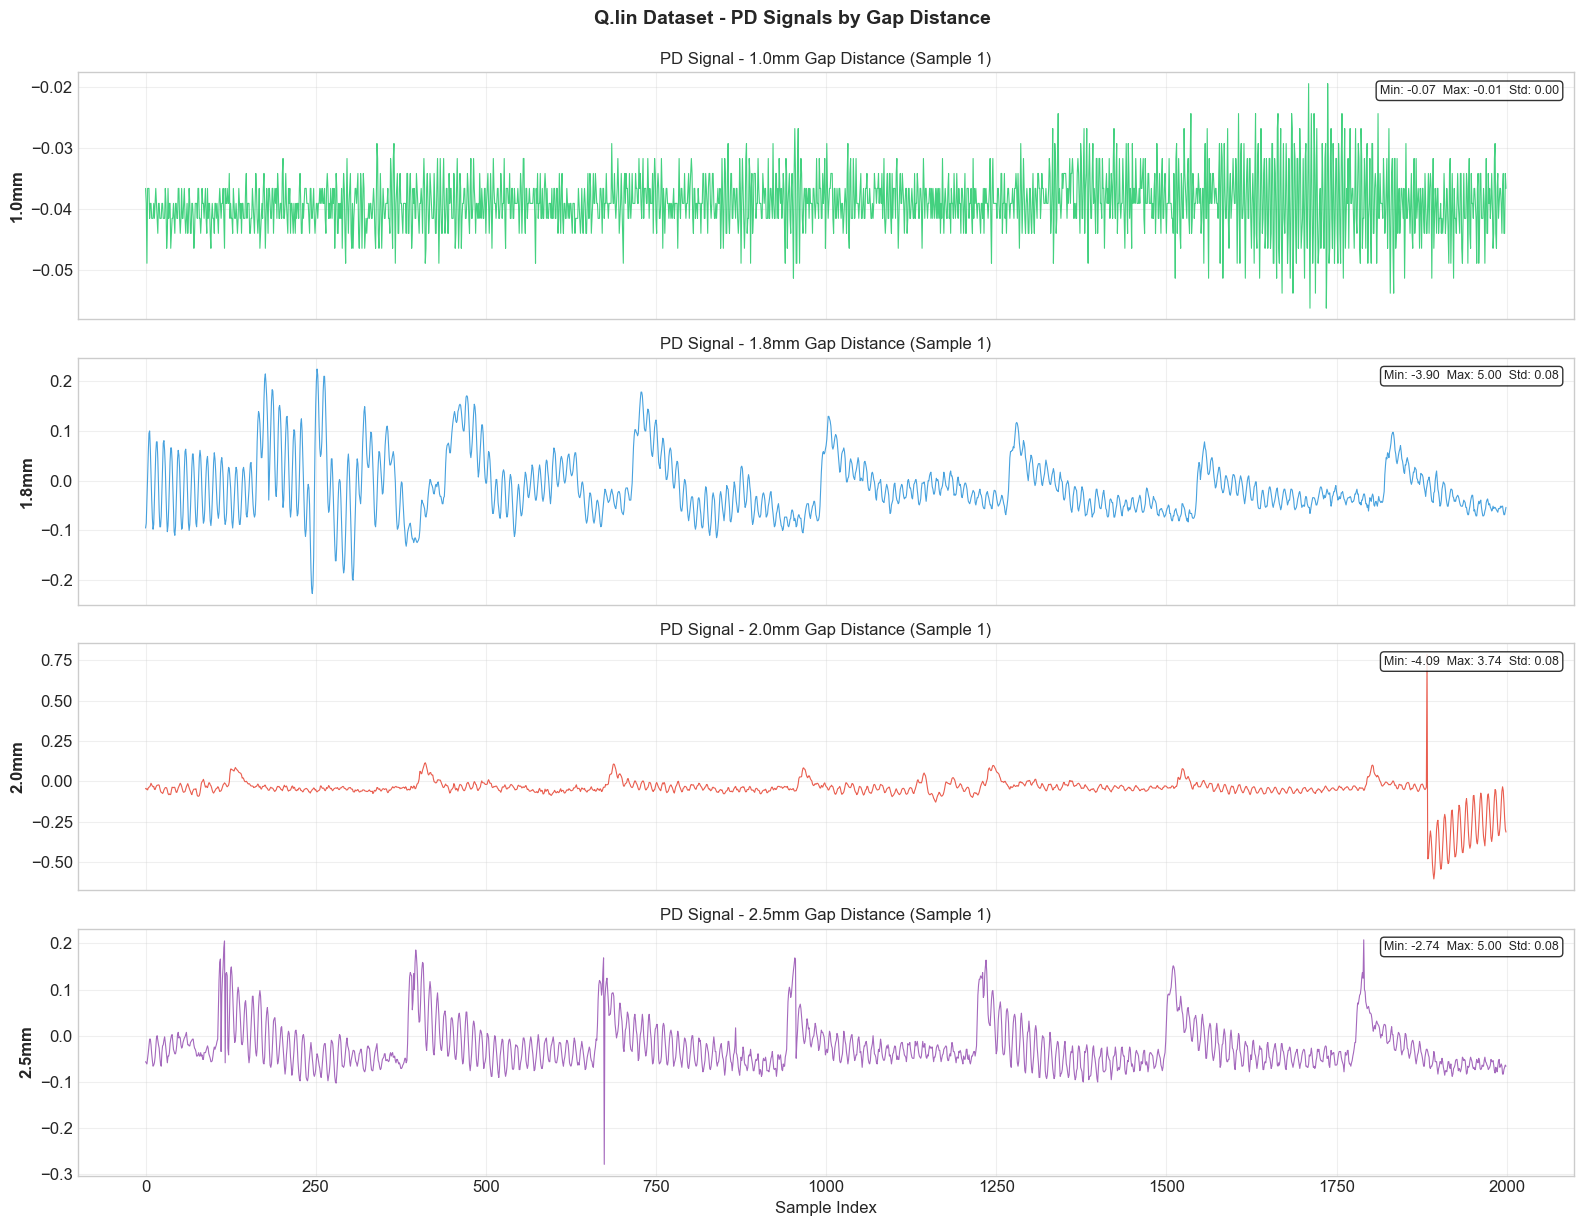

In [5]:
# Plot sample signals from each distance class
fig, axes = plt.subplots(len(datasets), 1, figsize=(16, 3 * len(datasets)), sharex=True)

if len(datasets) == 1:
    axes = [axes]

colors = ['#2ecc71', '#3498db', '#e74c3c', '#9b59b6']

for idx, (label, data) in enumerate(datasets.items()):
    ax = axes[idx]
    
    # Get first sample
    if data.ndim == 1:
        sample = data
    else:
        sample = data[0] if data.shape[0] < data.shape[1] else data[:, 0]
    
    # Plot
    ax.plot(sample[:2000], color=colors[idx % len(colors)], linewidth=0.8, alpha=0.9)
    ax.set_ylabel(f'{label}', fontsize=12, fontweight='bold')
    ax.set_title(f'PD Signal - {label} Gap Distance (Sample 1)', fontsize=12)
    ax.grid(True, alpha=0.3)
    
    # Add statistics
    stats_text = f'Min: {sample.min():.2f}  Max: {sample.max():.2f}  Std: {sample.std():.2f}'
    ax.text(0.99, 0.95, stats_text, transform=ax.transAxes, fontsize=9,
            verticalalignment='top', horizontalalignment='right',
            bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))

axes[-1].set_xlabel('Sample Index', fontsize=12)
plt.tight_layout()
plt.suptitle('Q.lin Dataset - PD Signals by Gap Distance', fontsize=14, fontweight='bold', y=1.02)
plt.show()

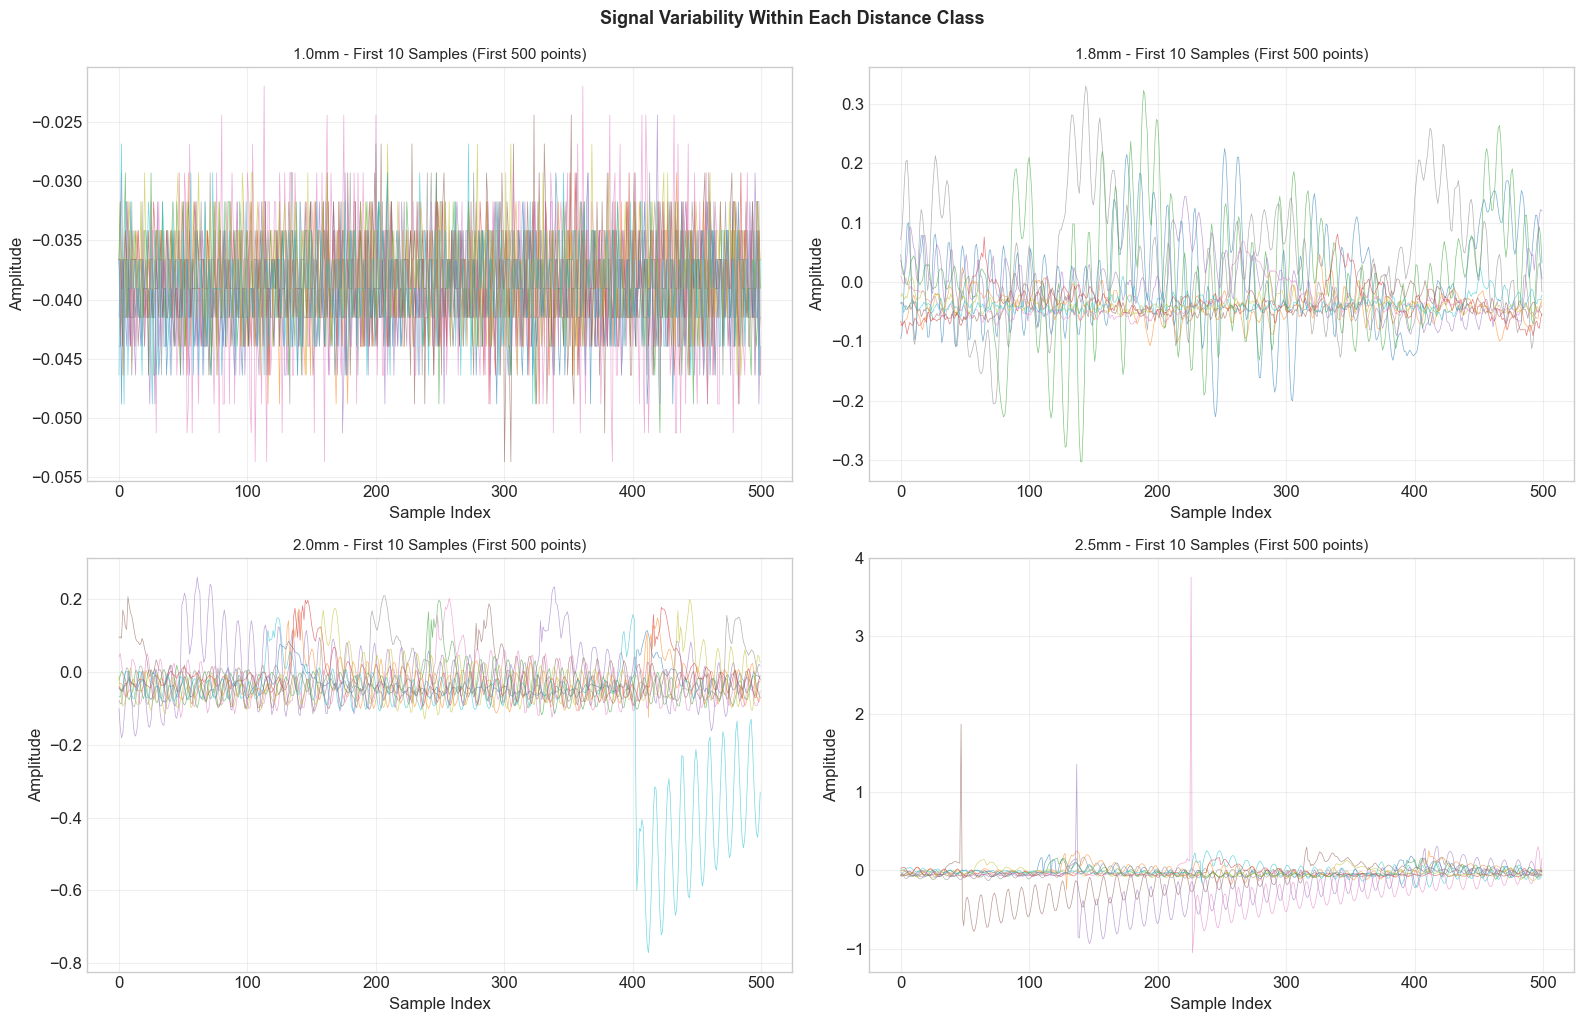

In [6]:
# Plot multiple samples overlay for each class
fig, axes = plt.subplots(2, 2, figsize=(16, 10))
axes = axes.flatten()

for idx, (label, data) in enumerate(datasets.items()):
    if idx >= 4:
        break
    ax = axes[idx]
    
    # Plot up to 10 samples
    n_samples = min(10, data.shape[0] if data.ndim > 1 else 1)
    
    for i in range(n_samples):
        if data.ndim == 1:
            sample = data
        else:
            sample = data[i] if data.shape[0] < data.shape[1] else data[:, i]
        ax.plot(sample[:500], alpha=0.6, linewidth=0.5)
    
    ax.set_title(f'{label} - First {n_samples} Samples (First 500 points)', fontsize=11)
    ax.set_xlabel('Sample Index')
    ax.set_ylabel('Amplitude')
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.suptitle('Signal Variability Within Each Distance Class', fontsize=13, fontweight='bold', y=1.02)
plt.show()

## 5. Noisy vs Clean Comparison

In [ ]:
if noisy_data is not None and '1.8mm' in datasets:
    fig, axes = plt.subplots(2, 1, figsize=(16, 8), sharex=True)
    
    # Clean signal (1.8mm ~ 18mm)
    clean_data = datasets['1.8mm']
    if clean_data.ndim == 1:
        clean_sample = clean_data
    else:
        clean_sample = clean_data[0] if clean_data.shape[0] < clean_data.shape[1] else clean_data[:, 0]
    
    # Noisy signal
    if noisy_data.ndim == 1:
        noisy_sample = noisy_data
    else:
        noisy_sample = noisy_data[0] if noisy_data.shape[0] < noisy_data.shape[1] else noisy_data[:, 0]
    
    # Match lengths
    plot_len = min(len(clean_sample), len(noisy_sample), 2000)
    
    axes[0].plot(clean_sample[:plot_len], color='#2ecc71', linewidth=0.8)
    axes[0].set_title('Clean Signal (1.8mm)', fontsize=12)
    axes[0].set_ylabel('Amplitude')
    axes[0].grid(True, alpha=0.3)
    
    axes[1].plot(noisy_sample[:plot_len], color='#e74c3c', linewidth=0.8)
    axes[1].set_title('Noisy Signal (-10dB SNR)', fontsize=12)
    axes[1].set_xlabel('Sample Index')
    axes[1].set_ylabel('Amplitude')
    axes[1].grid(True, alpha=0.3)
    
    plt.tight_layout()
    plt.suptitle('Clean vs Noisy Signal Comparison (18mm)', fontsize=14, fontweight='bold', y=1.02)
    plt.show()
    
    # Calculate SNR
    if len(clean_sample) == len(noisy_sample):
        noise = noisy_sample[:plot_len] - clean_sample[:plot_len]
        signal_power = np.mean(clean_sample[:plot_len]**2)
        noise_power = np.mean(noise**2)
        snr_estimated = 10 * np.log10(signal_power / noise_power) if noise_power > 0 else np.inf
        print(f"Estimated SNR: {snr_estimated:.2f} dB")
else:
    print("Cannot compare: missing noisy data or 1.8mm dataset")

## 6. Statistical Analysis

In [ ]:
# Calculate 9 features (matching senior's MATLAB method)
from scipy import stats

def calculate_9_features(signal):
    """Calculate the 9 statistical features used in senior's method."""
    features = {}
    
    # Time-domain features
    features['RMS'] = np.sqrt(np.mean(signal**2))
    features['Variance'] = np.var(signal)
    features['Std'] = np.std(signal)
    features['WaveformFactor'] = features['RMS'] / np.abs(np.mean(signal)) if np.mean(signal) != 0 else 0
    features['Kurtosis'] = stats.kurtosis(signal)
    features['Skewness'] = stats.skew(signal)
    
    # Frequency-domain features
    fft_vals = np.abs(np.fft.fft(signal))
    power_spectrum = fft_vals**2
    features['MaxPowerSpectrum'] = np.max(power_spectrum)
    
    freqs = np.fft.fftfreq(len(signal))
    positive_mask = freqs > 0
    
    if np.sum(power_spectrum[positive_mask]) > 0:
        cumsum = np.cumsum(power_spectrum[positive_mask])
        total = cumsum[-1]
        median_idx = np.searchsorted(cumsum, total / 2)
        features['MedianFreq'] = freqs[positive_mask][median_idx] if median_idx < len(freqs[positive_mask]) else 0
        features['MeanFreq'] = np.sum(freqs[positive_mask] * power_spectrum[positive_mask]) / total
    else:
        features['MedianFreq'] = 0
        features['MeanFreq'] = 0
    
    return features

# Calculate features for all datasets
all_features = {}

for label, data in datasets.items():
    print(f"\nProcessing {label}...")
    features_list = []
    
    # Get number of samples
    if data.ndim == 1:
        n_samples = 1
        samples = [data]
    else:
        n_samples = min(50, data.shape[0])  # Limit to 50 samples for speed
        samples = [data[i] if data.shape[0] < data.shape[1] else data[:, i] for i in range(n_samples)]
    
    for sample in samples:
        features_list.append(calculate_9_features(sample))
    
    all_features[label] = features_list
    print(f"  Calculated features for {len(features_list)} samples")

print("\nFeature extraction complete!")

In [ ]:
# Create feature comparison table
import pandas as pd

summary_data = []

for label, features_list in all_features.items():
    # Average across samples
    avg_features = {}
    for key in features_list[0].keys():
        values = [f[key] for f in features_list]
        avg_features[key] = f"{np.mean(values):.4f} ± {np.std(values):.4f}"
    avg_features['Class'] = label
    summary_data.append(avg_features)

df = pd.DataFrame(summary_data)
df = df.set_index('Class')
print("\n9 Features Comparison by Distance Class:")
print("=" * 100)
display(df.T)

## 7. Distribution Analysis

In [ ]:
# Box plots for key features across classes
fig, axes = plt.subplots(3, 3, figsize=(16, 12))
axes = axes.flatten()

feature_names = ['RMS', 'Variance', 'Std', 'WaveformFactor', 'Kurtosis', 
                 'Skewness', 'MaxPowerSpectrum', 'MedianFreq', 'MeanFreq']

for idx, feature in enumerate(feature_names):
    ax = axes[idx]
    data_for_plot = []
    labels_for_plot = []
    
    for label, features_list in all_features.items():
        values = [f[feature] for f in features_list]
        data_for_plot.append(values)
        labels_for_plot.append(label)
    
    bp = ax.boxplot(data_for_plot, labels=labels_for_plot, patch_artist=True)
    colors = ['#2ecc71', '#3498db', '#e74c3c', '#9b59b6']
    for patch, color in zip(bp['boxes'], colors[:len(bp['boxes'])]):
        patch.set_facecolor(color)
        patch.set_alpha(0.7)
    
    ax.set_title(feature, fontsize=11, fontweight='bold')
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.suptitle('Feature Distribution Across Distance Classes', fontsize=14, fontweight='bold', y=1.02)
plt.show()

## 8. Model Compatibility Check

In [ ]:
# Check signal length compatibility with MR-TAE-Fusion
REQUIRED_LENGTH = 2001  # Model expects this
REQUIRED_SAMPLE_RATE = 1e9  # 1 GHz

print("=" * 70)
print("MODEL COMPATIBILITY ANALYSIS")
print("=" * 70)
print(f"MR-TAE-Fusion expects: {REQUIRED_LENGTH} samples @ {REQUIRED_SAMPLE_RATE/1e6:.0f} MHz")
print("=" * 70)

for label, data in datasets.items():
    if data.ndim == 1:
        signal_len = len(data)
        n_signals = 1
    else:
        signal_len = data.shape[1] if data.shape[0] < data.shape[1] else data.shape[0]
        n_signals = data.shape[0] if data.shape[0] < data.shape[1] else data.shape[1]
    
    status = "✓ COMPATIBLE" if signal_len >= REQUIRED_LENGTH else "✗ TOO SHORT"
    action = "" if signal_len >= REQUIRED_LENGTH else f" (need padding or interpolation)"
    
    print(f"{label}: {n_signals} signals × {signal_len} samples - {status}{action}")

print("\nRecommendations:")
print("- For shorter signals: Use interpolation or zero-padding to reach 2001 samples")
print("- For longer signals: Segment into 2001-sample windows with overlap")

## 9. Summary & Recommendations

In [ ]:
print("\n" + "="*70)
print("EDA SUMMARY")
print("="*70)

print("\n1. DATASETS LOADED:")
for label, data in datasets.items():
    shape = data.shape if hasattr(data, 'shape') else 'unknown'
    print(f"   - {label}: {shape}")

print("\n2. CLASSIFICATION SCHEME:")
print("   - 4 distance-based classes: 1.0mm, 1.8mm, 2.0mm, 2.5mm")
print("   - These correspond to: 10mm, 18mm, 20mm, 25mm gap distances")

print("\n3. DATA CHARACTERISTICS:")
print("   - Simulated data: 1.0mm, 1.8mm, 2.0mm")
print("   - Real-world data: 2.5mm (for testing)")

print("\n4. RECOMMENDED PIPELINE:")
print("   Step 1: Preprocess signals to 2001 samples")
print("   Step 2: Apply MR-TAE-Fusion for denoising")
print("   Step 3: Train 4-class distance classifier")
print("   Step 4: Evaluate on real-world 2.5mm data")

print("\n5. 25mm vs 2.5mm:")
print("   - '25mm' folder (PNGs): pre-processed simulated data")
print("   - 'data2.5mm.mat': raw real-world measurements")
print("   - Use data2.5mm.mat for real-world testing")

print("\n" + "="*70)